# Chance level IM vs IP with Covariance Matrix, tangent space with Riemann and LDA

**Three questions:**
1. How many epochs are needed (approx.) to overcome the chance level in IM vs IP?
2. For each electrode, from what moment is the chance level exceeded?
3. At group level, where and when can we say that accuracy exceeds chance?

**Methodology:**
- Surrogate by tag permutation, **per subject × electrode × time window**.
- ΔAcc = Acc_actual(t) − Acc_chance(t)
- Group contrast: paired t-test one-tailed vectorized + FDR per cell (channel, t).
- Parallelism: `joblib.Parallel` (N_JOBS) on subjects.
- Intermediate results with high computational cost are saved to disk to avoid recalculation if the kernel crashes.


In [19]:
import warnings
from pathlib import Path
from scipy.signal import hilbert
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import numpy as np
import pandas as pd
import joblib
from joblib import Parallel, delayed, cpu_count
from scipy.stats import ttest_rel
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve, average_precision_score

# !pip install -q pyriemann
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
import sys

# Add src directory to path so we can import br_analysis
src_path = Path(r"c:\Users\nils\Documents\Universitat\TFG\src")
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from br_analysis import (
    detect_project_paths,
    get_task_config,
    get_epochs_grid,
    TARGET_BANDS_CLUSTERS,
    COMMON_BAND_RANGES,
)

from br_analysis.experiments import (
    ChanceLevelExperiment,
    TimeWindowGrid,
    ExperimentSettings,
    choose_n_splits,
    temporal_stratified_splits,
)
from br_analysis.models import RiemannLdaModelFactory

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

if IN_COLAB:
    drive.mount("/content/drive")

paths = detect_project_paths("im_vs_ip_riemann", in_colab=IN_COLAB)
PROJECT_DIR = paths.project_dir
BASE_DIR = paths.project_dir
DATA_DIR = paths.data_dir
ANALYSIS_ROOT = paths.analysis_root
ANALYSIS_DIR = paths.analysis_dir
CACHE_DIR = paths.cache_dir
TABLES_DIR = paths.tables_dir
FIGURES_DIR = paths.figures_dir
DATA_FILES = paths.data_files

## Configuration

## Super-Covariance: Multi-Network Fusion (Theta + Alpha)

1. **Independent filtering:** Theta (5–7 Hz, 9 frontomedial channels) and Alpha (8–12 Hz, 13 parieto-occipital channels)
2. **Concatenation:** Form (trials, 22, times) ← stack in axis=1
3. **Covariance 22×22:** Per subject, per trial, per time window
   - **Diagonal:** Intra-band power (Theta²_ch1, ..., Alfa²_ch1, ...)
   - **Off-diagonal:** Cross covariances **Theta ↔ Alpha** (key!)
4. **Riemann tangent space:** LDA discriminates how the Alpha energy falls **when the Theta energy rises**
   - When the ACC details error (theta ↑) → visual suppression (alpha ↓)

In [2]:
TASK_TAG = "im_vs_ip_riemann_fused"
RECALCULAR_CHANCE_LEVEL = False
ANALYSIS_WINDOW = (0.0, 1.5)

# ========== SUPER-COVARIANCE: Multi-Network Fusion (Theta + Alpha) ==========
TARGET_BANDS_CLUSTERS = TARGET_BANDS_CLUSTERS
BAND_RANGES = COMMON_BAND_RANGES

# Mode: "fused" = concatenate Theta + Alpha in the channel axis
CHANNEL_MODE = ["fused"]

# Centralized task config and epochs grid
TASK = get_task_config("im_vs_ip", ANALYSIS_ROOT, name="im_vs_ip_riemann_fused", analysis_window=ANALYSIS_WINDOW)
EPOCHS_GRID = get_epochs_grid("im_vs_ip")

# Map of conditions, subjects, etc. from the centralized configuration
COND_EVENTS_CODES = TASK.event_codes
COND_EVENTS = TASK.cond_events
SELECTED_SUBJECTS_CSV = TASK.selected_subjects_csv
MAX_SUBJECTS = TASK.max_subjects
UNDERSAMPLE_CLASSES = TASK.undersample_classes

# Output directories
RESULTS_DIR = ANALYSIS_DIR
CACHE_EPOCHS_DIR = CACHE_DIR
CACHE_MAP_FILE = CACHE_DIR / f"tensors_map_{TASK_TAG}.npz"
EPOCHS_CSV = TABLES_DIR / "epochs_grid_riemann.csv"
ONSET_CSV = TABLES_DIR / "onset_summary_riemann.csv"

# Time×electrode map
MAP_WINDOW_SEC = 0.500  # time window width (s)
MAP_STEP_SEC = 0.1  # step(s) - increased efficiently
MAP_CV_MAX_SPLITS = 5

# Surrogate
N_PERM_SURROGATE = 100

# grid epochs
N_REPEATS_EPOCHS = 10
N_JOBS = cpu_count() - 2 if cpu_count() > 4 else cpu_count()

RANDOM_SEED = TASK.random_seed

print(f"BASE_DIR: {BASE_DIR}")
print(f"ANALYSIS_ROOT: {ANALYSIS_ROOT}")
print(f"RESULTS_DIR: {RESULTS_DIR}")
print(f"CACHE_DIR: {CACHE_DIR}")
print(f"TABLES_DIR: {TABLES_DIR}")
print(f"FIGURES_DIR: {FIGURES_DIR}")
print(f"SELECTED_SUBJECTS_CSV: {SELECTED_SUBJECTS_CSV}")
print(f"TARGET_BANDS_CLUSTERS: {TARGET_BANDS_CLUSTERS}")
print(f"BAND_RANGES: {BAND_RANGES}")
print(f"COND_EVENTS_CODES: {COND_EVENTS_CODES}")
print(f"COND_EVENTS (tags): {COND_EVENTS}")
# Unified experiment settings and runner
settings = ExperimentSettings(
    task_tag=TASK_TAG,
    random_seed=RANDOM_SEED,
    map_cv_max_splits=MAP_CV_MAX_SPLITS,
    n_perm_surrogate=N_PERM_SURROGATE,
    epochs_grid=EPOCHS_GRID,
    n_repeats_epochs=N_REPEATS_EPOCHS,
    n_jobs=N_JOBS,
    recalculate=RECALCULAR_CHANCE_LEVEL,
)
model_factory = RiemannLdaModelFactory()
experiment = ChanceLevelExperiment(
    settings=settings,
    model_factory=model_factory,
)

BASE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
ANALYSIS_ROOT: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi
RESULTS_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann
CACHE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\cache
TABLES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\tables
FIGURES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\figures
SELECTED_SUBJECTS_CSV: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\exploration\tables\subjectes_seleccionats_im_vs_ip.csv
TARGET_BANDS_CLUSTERS: {'theta': ['Fp1', 'Fp2', 'Fz', 'F1', 'F2', 'FCz', 'FC1', 'FC2', 'Cz'], 'alpha': ['Pz', 'P1', 'P2', 'P3', 'P4', 'P7', 'P8', 'Oz', 'O1', 'O2', 'PO3

## 1. Loading data

In [3]:
def load_chance_epochs():
    """Load the subjects, filter the bands and select the required channel clusters.

    For MULTI-NETWORK FUSION (Super-Covariance):
    - Filter Theta and Alpha independently
    - Concatenate the channels in the axis of the channels (axis=1) to capture cross correlations
    - Return X_dict['fused'] = (trials, theta_chs + alfa_chs, times)
    """
    cache_file = CACHE_DIR / f"cache_epochs_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else 'all'}.joblib"
    if cache_file.exists():
        print(f"Loading cached epochs from {cache_file}...")
        return joblib.load(cache_file)
    df_sel = pd.read_csv(SELECTED_SUBJECTS_CSV)

    subject_ids = df_sel["subject"].dropna().astype(str).tolist()
    subject_ids = list(dict.fromkeys(subject_ids))
    if MAX_SUBJECTS is not None:
        subject_ids = subject_ids[:MAX_SUBJECTS]
    print(f"Selected subjects to load: {len(subject_ids)}")

    fif_by_subject = {p.stem: p for p in DATA_FILES}

    # Estructura: X_blocks["theta"] = [(trials, channels, times), ...], X_blocks["alpha"] = [...]
    X_blocks = {band: [] for band in TARGET_BANDS_CLUSTERS}
    y_blocks = []
    subj_blocks = []
    skipped = []

    # Store dynamic channel names available per band
    avail_ch_names = {band: [] for band in TARGET_BANDS_CLUSTERS}
    first_subject_times = None

    for subj_name in subject_ids:
        fif_path = fif_by_subject.get(subj_name)
        if fif_path is None:
            skipped.append(f"{subj_name}: fitxer .fif no trobat")
            continue

        ep = mne.read_epochs(fif_path, preload=False)
        ep.load_data()  # Load data after reviewing channels to save memory if subject is skipped

        for ch_idx, ch_name in enumerate(ep.ch_names):
            if ep.info["chs"][ch_idx]["unit"] == 0:
                ep.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
                ep.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

        ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")
        ep = ep.copy().pick(mne.pick_types(ep.info, eeg=True))

        # The actual selection is made by the codes of 01; tags are kept for reference only.
        im_codes = COND_EVENTS_CODES[TASK.class_0]
        ip_codes = COND_EVENTS_CODES[TASK.class_1]
        events = ep.events[:, 2]
        im_mask = np.isin(events, im_codes)
        ip_mask = np.isin(events, ip_codes)
        if not im_mask.any() or not ip_mask.any():
            skipped.append(
                f"{fif_path.name}: missing required codes (IM={int(im_mask.sum())}, IP={int(ip_mask.sum())})"
            )
            continue
        ep = ep[im_mask | ip_mask].copy().crop(tmin=ANALYSIS_WINDOW[0], tmax=ANALYSIS_WINDOW[1])

        if first_subject_times is None:
            first_subject_times = np.array(ep.times, dtype=np.float32)

        events = ep.events[:, 2]
        y_s = np.where(np.isin(events, im_codes), 0, 1).astype(np.int8)

        n_im, n_ip = int((y_s == 0).sum()), int((y_s == 1).sum())
        if min(n_im, n_ip) == 0:
            skipped.append(f"{fif_path.name}: classe buida (IM={n_im}, IP={n_ip})")
            continue

        if UNDERSAMPLE_CLASSES:
            n_min = min(n_im, n_ip)
            rng = np.random.default_rng(RANDOM_SEED + sum(bytearray(subj_name.encode("utf-8"))))
            idx_im = np.where(y_s == 0)[0]
            idx_ip = np.where(y_s == 1)[0]
            keep_idx = np.concatenate(
                [rng.choice(idx_im, n_min, replace=False), rng.choice(idx_ip, n_min, replace=False)]
            )
            rng.shuffle(keep_idx)
            ep = ep[keep_idx]
            y_s = y_s[keep_idx]

        valid_for_subject = True
        subj_band_data = {}
        for band, target_channels in TARGET_BANDS_CLUSTERS.items():
            avail_chs = [ch for ch in target_channels if ch in ep.ch_names]
            if len(avail_chs) < len(target_channels) * 0.5:  # Require at least half the cluster
                skipped.append(f"{fif_path.name}: too few channels for the cluster {band}")
                valid_for_subject = False
                break

            avail_ch_names[band] = avail_chs

            l_freq, h_freq = BAND_RANGES[band]
            ep_band = ep.copy().pick(avail_chs)
            ep_band._data = np.ascontiguousarray(ep_band._data)
            ep_band.filter(
                l_freq=l_freq,
                h_freq=h_freq,
                method="fir",
                phase="zero-double",
                verbose=False,
            )
            subj_band_data[band] = ep_band.get_data().astype(np.float32)

        if not valid_for_subject:
            continue

        for band in TARGET_BANDS_CLUSTERS:
            X_blocks[band].append(subj_band_data[band])

        y_blocks.append(y_s)
        subj_blocks.extend([subj_name] * len(y_s))

    # Concatenate by band first
    X_dict = {band: np.concatenate(blocks, axis=0) for band, blocks in X_blocks.items()}

    # ===== MULTI-NETWORK MERGER =====
    # Concatenate Theta and Alpha in the channel axis (axis=1)
    # Forma: (trials, theta_channels + alfa_channels, times)
    if "theta" in X_dict and "alpha" in X_dict:
        X_fused = np.concatenate([X_dict["theta"], X_dict["alpha"]], axis=1)
        X_dict["fused"] = X_fused
        n_theta_chs = X_dict["theta"].shape[1]
        n_alpha_chs = X_dict["alpha"].shape[1]
        print(f"  Multi-network fusion: Theta ({n_theta_chs}) + Alfa ({n_alpha_chs}) = {X_fused.shape[1]} channels")

    y = np.concatenate(y_blocks, axis=0)
    subj_list = np.array(subj_blocks, dtype=object)

    print(f"Total Samples: {len(y)} | IM={(y==0).sum()} | IP={(y==1).sum()}")
    print(f"Loaded subjects: {len(np.unique(subj_list))}")
    for band in TARGET_BANDS_CLUSTERS:
        print(f"Cluster channels {band}: {avail_ch_names[band]}")

    if skipped:
        print("Omesos:")
        for m in skipped:
            print(f"  {m}")

    ret_val = (X_dict, y, subj_list, avail_ch_names, first_subject_times)
    joblib.dump(ret_val, cache_file, compress=3)
    print(f"Saved loaded epochs to cache: {cache_file}")
    return X_dict, y, subj_list, avail_ch_names, first_subject_times


X_dict, y, subj_list, ch_names_dict, times = load_chance_epochs()

Selected subjects to load: 29
  Multi-network fusion: Theta (9) + Alfa (13) = 22 channels
Total Samples: 5726 | IM=2863 | IP=2863
Loaded subjects: 29
Cluster channels theta: ['Fp1', 'Fp2', 'Fz', 'F1', 'F2', 'FCz', 'FC1', 'FC2', 'Cz']
Cluster channels alpha: ['Pz', 'P1', 'P2', 'P3', 'P4', 'P7', 'P8', 'Oz', 'O1', 'O2', 'PO3', 'PO4', 'POz']
Saved loaded epochs to cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\cache\cache_epochs_im_vs_ip_riemann_fused_sub29.joblib


## 2. Pipeline Design and Validation Method

To validate whether our classification results are real or the result of chance (chance level), we implement a centralized rigorous pipeline in the `ChanceLevelExperiment` class of `br_analysis.experiments`. This ensures that all classical ranking analyzes follow the same logic and ensures consistency of results.

This pipeline is structured in two experiments:
1. **Grid of Epochs (Epochs Grid)**: To study how many trials the model needs to obtain a performance statistically superior to chance.
2. **Time-Band Map (Time-Feature Map)**: To identify in which temporal windows and in which frequency bands the relevant information is concentrated.

```mermaid
graph TD
    A[Epoch Data Loading by Subject] --> B[Epoch Balanced Subsampling]
    B --> C[Temporal Stratified Cross-Validation]
    C --> D[Feature Extraction: Riemann Covariance Matrices]
    D --> E[Classifier Training: Tangent Space + LDA]
    E --> F[Real Accuracy Calculation]
    E --> G[Generating Surrogate Distributions via Label Permutation]
    F --> H[Comparison: Accuracy Delta and Q95 Threshold]
    G --> H
    H --> I[Group Analysis: Paired t-test and Hit-rate]
```

### Key Components of the Pipeline

1. **Balanced Subsampling (`balanced_sample`)**:
   - Before training the model on a subset of epochs (from 20 to 190, in steps of 10), random sampling is performed per subject so that the number of epochs per class is strictly balanced (the same number of epochs in each class, e.g. IM and IP or C and I).
   - This sets the a priori probability of each class at exactly 50%, eliminating biases that could alter the accuracy.

2. **Temporal Stratified Cross Validation (`temporal_stratified_splits`)**:
   - EEG-type signals have a strong temporal dependence. To prevent information from the future leaking into the past (*data leakage*), we use a *forward-chaining* cross-validation. Test sets are always later in time than train sets.
   - The number of partitions (folds) is dynamically adapted per subject based on the least frequent class in the sample (`choose_n_splits(y_s, max_splits=5)`). In case of highly asymmetric distributions or extreme random permutations where the net temporal match fails, the function has fallbacks to a randomized 2-fold.

3. **Extraction of Characteristics and Classification**:
   - **Characteristics**: The covariance matrices are calculated for each trial and selected frequency band, and are projected onto the Riemann tangent space, allowing linear operations to be performed on non-Euclidean metrics.
   - **Classifier**: An LDA (Linear Discriminant Analysis) combined with Riemann preprocessing (`RiemannLdaModelFactory`) is trained and evaluated.

4. **Chance Level and Surrogate Distributions**:
   - For each time setting or number of epochs, we calculate:
     - **Accuracy Real (`acc_real_mean`)**: Average of the cross-validation accuracies with the real labels.
     - **Distribution of Chance / Surrogates**: Real labels are shuffled randomly $N$ times (default 50). For each permutation, the entire cross-validation process is repeated.
     - **Q95 Threshold (`acc_chance_q95`)**: The 95th percentile of the accuracies of the surrogate distribution. If the actual accuracy of the subject exceeds this threshold, we consider the classification to be statistically significant ($p < 0.05$).

5. **Group Statistical Analysis**:
   - To evaluate group-level significance for each cell (channel/band, time), we perform a **paired t-test** of the actual accuracy vs. the average chance of each subject.
   - A cell is considered **robust** if the t-test is significant ($p < 0.05$ from the upper tail) **and** the group *hit-rate* is $\ge 0.50$ (at least half of the subjects individually exceed their Q95 threshold).


## 3. Execution (parallel by subject)

In [4]:
subject_ids = pd.unique(subj_list).tolist()

CACHE_EPOCHS = CACHE_EPOCHS_DIR / (
    f"epochs_grid_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else len(subject_ids)}.csv"
)

print(
    f"Grid epochs — {len(subject_ids)} subj × {len(CHANNEL_MODE)} × clusters "
    f"{len(EPOCHS_GRID)} punts × {N_REPEATS_EPOCHS} reps …"
)

with joblib.parallel_backend("loky", n_jobs=N_JOBS):
    df_epochs = experiment.run_epochs_grid(X_dict, y, subj_list, CHANNEL_MODE, cache_file=CACHE_EPOCHS)

df_epochs.to_csv(EPOCHS_CSV, index=False)
print(f"Saved table: {EPOCHS_CSV}")
df_epochs.head(10)

Grid epochs — 29 subj × 1 × clusters 8 punts × 10 reps …


Epochs Grid (im_vs_ip_riemann_fused):   0%|          | 0/29 [00:00<?, ?it/s]

Saved cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\cache\epochs_grid_im_vs_ip_riemann_fused_sub29.csv
Saved table: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\tables\epochs_grid_riemann.csv


,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P002,fused,20,0.435000,0.120520,0.493400,0.700000,-0.058400,-0.265000
1,P002,fused,40,0.515000,0.061779,0.500767,0.633333,0.014233,-0.118333
2,P002,fused,60,0.476000,0.066813,0.499560,0.620000,-0.023560,-0.144000
3,P002,fused,100,0.506250,0.042989,0.497547,0.587569,0.008703,-0.081319
4,P002,fused,150,0.485769,0.026985,0.498523,0.566667,-0.012754,-0.080897
5,P002,fused,200,0.488529,0.024808,0.504279,0.561526,-0.015749,-0.072996
6,P003,fused,20,0.460000,0.144568,0.494600,0.700000,-0.034600,-0.240000
7,P003,fused,40,0.496667,0.088207,0.496250,0.650000,0.000417,-0.153333
8,P003,fused,60,0.510000,0.061482,0.496720,0.600000,0.013280,-0.090000
9,P003,fused,100,0.507083,0.054364,0.496228,0.586111,0.010856,-0.079028


In [5]:
# Show df_epochs sorted by delta_acc_q95 descending
df_epochs_sorted = df_epochs.sort_values("delta_acc_q95", ascending=False).reset_index(drop=True)
display(df_epochs_sorted.head(10**6))

,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P057,fused,240,0.685000,1.110223e-16,0.502640,0.555000,0.182360,0.130000
1,P057,fused,200,0.679926,1.922847e-02,0.503433,0.565846,0.176493,0.114081
2,P057,fused,150,0.668718,2.244103e-02,0.503722,0.579519,0.164996,0.089199
3,P057,fused,100,0.650000,4.522321e-02,0.503586,0.591806,0.146414,0.058194
4,P017,fused,200,0.575551,1.729446e-02,0.503905,0.559577,0.071646,0.015974
...,...,...,...,...,...,...,...,...,...
157,P022,fused,20,0.455000,1.890106e-01,0.498600,0.702500,-0.043600,-0.247500
158,P002,fused,20,0.435000,1.205197e-01,0.493400,0.700000,-0.058400,-0.265000
159,P053,fused,20,0.425000,1.006231e-01,0.490500,0.700000,-0.065500,-0.275000
160,P005,fused,20,0.425000,6.020797e-02,0.499400,0.700000,-0.074400,-0.275000


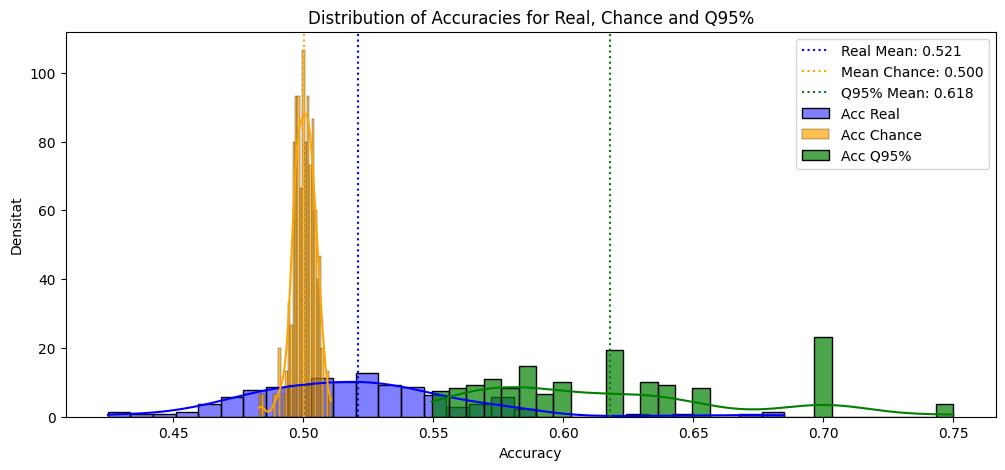

In [6]:
# Histogram acc_real_mean, acc_chance_mean and acc_chance_q95 with seaborn
plt.figure(figsize=(12, 5))
sns.histplot(df_epochs, x="acc_real_mean", color="blue", label="Acc Real", kde=True, stat="density", bins=30)
sns.histplot(
    df_epochs, x="acc_chance_mean", color="orange", label="Acc Chance", kde=True, stat="density", bins=30, alpha=0.7
)
sns.histplot(
    df_epochs, x="acc_chance_q95", color="green", label="Acc Q95%", kde=True, stat="density", bins=30, alpha=0.7
)
plt.title("Distribution of Accuracies for Real, Chance and Q95%")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
# Show averages of the three groups
mean_real = df_epochs["acc_real_mean"].mean()
mean_chance = df_epochs["acc_chance_mean"].mean()
mean_q95 = df_epochs["acc_chance_q95"].mean()

plt.axvline(mean_real, color="blue", linestyle=":", label=f"Real Mean: {mean_real:.3f}")
plt.axvline(mean_chance, color="orange", linestyle=":", label=f"Mean Chance: {mean_chance:.3f}")
plt.axvline(mean_q95, color="green", linestyle=":", label=f"Q95% Mean: {mean_q95:.3f}")
plt.legend()
plt.savefig(FIGURES_DIR / f"histogram_epochs_{TASK_TAG}.png")
plt.show()

## 5. Numeric summary epochs → accuracy

This cell leaves only the numerical summary of the grid.
All figures are centralized in section 7.

In [7]:
# Numeric summary of the epoch grid
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

df_surpass = df_epochs[df_epochs["acc_real_mean"] > df_epochs["acc_chance_q95"]]

print("Performance summary (epochs grid):")
print(f"- Files totals: {len(df_epochs)}")
print(f"- Unique subjects: {df_epochs['subject'].nunique()}")
print(f"- Single electrodes: {df_epochs['electrode'].nunique()}")
print(f"- n_epochs provats: {sorted(df_epochs['n_epochs_total'].unique().tolist())}")
print(f"- Global real mean Acc: {df_epochs['acc_real_mean'].mean():.4f}")
print(f"- Global mean chance q95: {df_epochs['acc_chance_q95'].mean():.4f}")

if not df_surpass.empty:
    print(f"- Minimum epochs to overcome q95: {int(df_surpass['n_epochs_total'].min())}")
    print(
        f"- Combinations exceeding q95: {len(df_surpass)}/{len(df_epochs)} "
        f"({100*len(df_surpass)/len(df_epochs):.1f}%)"
    )
else:
    print("- No combinations exceed the chance q95 in the current grid.")

display(grp.head(10))

Performance summary (epochs grid):
- Files totals: 162
- Unique subjects: 29
- Single electrodes: 1
- n_epochs provats: [20, 40, 60, 100, 150, 200, 240, 270]
- Global real mean Acc: 0.5210
- Global mean chance q95: 0.6180
- Minimum epochs to overcome q95: 60
- Combinations exceeding q95: 9/162 (5.6%)


,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95
0,20,0.503966,0.117467,0.499197,0.707155
1,40,0.523937,0.081975,0.501067,0.641149
2,60,0.512207,0.062445,0.500497,0.615931
3,100,0.527189,0.045879,0.500428,0.589432
4,150,0.528340,0.031746,0.500663,0.574220
5,200,0.534328,0.024605,0.500775,0.563645
6,240,0.542929,0.016228,0.499711,0.557893
7,270,0.518691,0.013701,0.499932,0.552656


## 5. Time×electrode map (parallel calculation)

### Note on features per window
Each `MAP_WINDOW_SEC` window is classified using **all time points
of the window** as features (`trials × win_samples` array in LR).
This is much more informative than using the average (1 feature), but increases the
computational cost — hence the need for parallelism.


In [8]:
subject_ids = pd.unique(subj_list).tolist()

# Defineix finestres temporals via TimeWindowGrid
windows = TimeWindowGrid.from_times(times, window_sec=MAP_WINDOW_SEC, step_sec=MAP_STEP_SEC)
starts = windows.starts
stops = windows.stops
window_centers = windows.centers
n_w, n_bands = len(window_centers), len(CHANNEL_MODE)

print(f"Finestres: {n_w} | width={MAP_WINDOW_SEC*1000:.0f}ms, pas={MAP_STEP_SEC*1000:.0f}ms")
print(f"Clusters (Bands): {n_bands} | Subjects: {len(subject_ids)}")
print("Features: covariance on each of the samples in the window.")
print(
    f"Total surrogates to be calculated: {len(subject_ids)} × {n_bands} × {n_w} × {N_PERM_SURROGATE:,} = "
    f"{len(subject_ids)*n_bands*n_w*N_PERM_SURROGATE:,}"
)

Finestres: 11 | width=500ms, pas=100ms
Clusters (Bands): 1 | Subjects: 29
Features: covariance on each of the samples in the window.
Total surrogates to be calculated: 29 × 1 × 11 × 100 = 31,900


In [9]:
subject_ids = pd.unique(subj_list).tolist()

print("Running time×cluster map (parallel by subject) …")
print(f"Subjects: {len(subject_ids)}")

with joblib.parallel_backend("loky", n_jobs=N_JOBS):
    map_data = experiment.run_time_map(X_dict, y, subj_list, CHANNEL_MODE, windows, cache_file=CACHE_MAP_FILE)

real_map = map_data["real_map"]
surr_mean = map_data["surr_mean"]
surr_q95 = map_data["surr_q95"]

delta_map = real_map - surr_mean  # ΔAcc(s, ch, t)
above_q95_map = real_map > surr_q95  # bool(s, ch, t)

print(f"Tensors shape: real_map={real_map.shape}  (subj, cluster, window)")

Running time×cluster map (parallel by subject) …
Subjects: 29


Time Map (im_vs_ip_riemann_fused):   0%|          | 0/29 [00:00<?, ?it/s]

Saved time map to cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\cache\tensors_map_im_vs_ip_riemann_fused.npz
Tensors shape: real_map=(29, 1, 11)  (subj, cluster, window)


## 6. Group statistic: paired t-test per cell (channel, t)

For each cell $(ch, t)$ we compare:
- **real_map[:, ch, t]**: real accuracy of each subject
- **surr_mean[:, ch, t]**: accuracy of chance (surrogate mean) of the same subject

Hypothesis H₁ (one-tailed): Acc_real > Acc_chance → only p/2 if t > 0.
Robust final criterion: `p < 0.05` **i** `ΔAcc_grupal > 0` **i** `hit-rate ≥ 0.50`.


In [10]:
n_subj_arr = real_map.shape[0]
p_map = np.full((n_bands, n_w), np.nan, dtype=np.float64)
t_map = np.full((n_bands, n_w), np.nan, dtype=np.float64)

for b_idx in range(n_bands):
    for wi in range(n_w):
        a = real_map[:, b_idx, wi]
        b = surr_mean[:, b_idx, wi]
        valid = ~np.isnan(a) & ~np.isnan(b)
        if valid.sum() < 6:
            continue
        t_stat, p_two = ttest_rel(a[valid], b[valid])
        t_map[b_idx, wi] = t_stat
        # One-tailed: p/2 si t > 0 (direccional: real > chance)
        p_map[b_idx, wi] = (p_two / 2) if t_stat > 0 else 1.0

mean_delta_map = np.nanmean(delta_map, axis=0)  # (n_bands, n_w)
hit_rate_map = np.nanmean(above_q95_map.astype(float), axis=0)

sig_map = (p_map < 0.05) & (mean_delta_map > 0)

# Onset by cluster: first instant with significant overshoot
onset_time_per_ch = np.full(n_bands, np.nan, dtype=np.float32)
for b_idx in range(n_bands):
    sig_idx = np.where(sig_map[b_idx])[0]
    if len(sig_idx) > 0:
        onset_time_per_ch[b_idx] = float(window_centers[sig_idx[0]])

# Criteri robust: p<0.05 + ΔAcc>0 + hit-rate≥0.5
robust_map = sig_map & (hit_rate_map >= 0.50)

n_sig = int(np.sum(sig_map))
n_rob = int(np.sum(robust_map))
print(f"Significant cells (p<0.05, ΔAcc>0): {n_sig} / {n_bands*n_w}")
print(f"Robust cells (+hit-rate≥0.5):         {n_rob} / {n_bands*n_w}")

Significant cells (p<0.05, ΔAcc>0): 6 / 11
Robust cells (+hit-rate≥0.5):         0 / 11


## 7. Visualitzacions

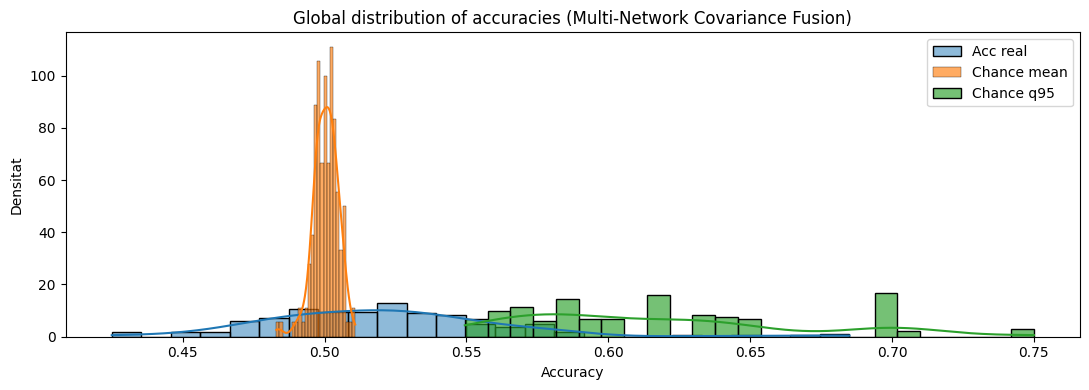

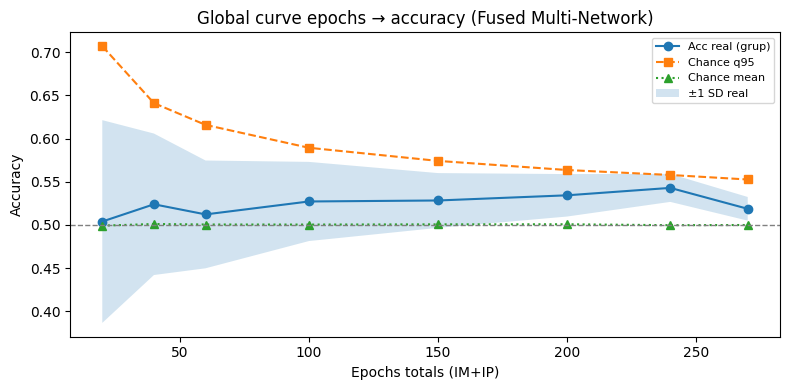

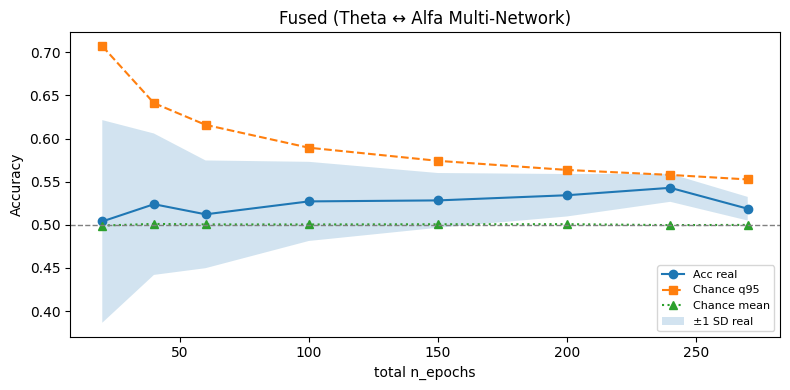

In [11]:
target_electrodes = CHANNEL_MODE  # ["fused"] for multi-network
df_two = df_epochs[df_epochs["electrode"].isin(target_electrodes)].copy()

# 7a) Distribucions globals (real vs chance)
plt.figure(figsize=(11, 4))
sns.histplot(df_epochs, x="acc_real_mean", color="tab:blue", label="Acc real", kde=True, stat="density", bins=25)
sns.histplot(
    df_epochs,
    x="acc_chance_mean",
    color="tab:orange",
    label="Chance mean",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
sns.histplot(
    df_epochs,
    x="acc_chance_q95",
    color="tab:green",
    label="Chance q95",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
plt.title("Global distribution of accuracies (Multi-Network Covariance Fusion)")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07a_dist_accuracies_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7b) Curve epochs -> accuracy (group)
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

plt.figure(figsize=(8, 4))
plt.plot(grp["n_epochs_total"], grp["acc_real_mean"], "o-", label="Acc real (grup)")
plt.plot(grp["n_epochs_total"], grp["acc_chance_q95"], "s--", label="Chance q95")
plt.plot(grp["n_epochs_total"], grp["acc_chance_mean"], "^:", label="Chance mean")
plt.fill_between(
    grp["n_epochs_total"],
    grp["acc_real_mean"] - grp["acc_real_std"],
    grp["acc_real_mean"] + grp["acc_real_std"],
    alpha=0.2,
    label="±1 SD real",
)
plt.axhline(0.5, linestyle="--", color="gray", linewidth=1)
plt.xlabel("Epochs totals (IM+IP)")
plt.ylabel("Accuracy")
plt.title("Global curve epochs → accuracy (Fused Multi-Network)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07b_epochs_accuracy_curve_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7c) Curves per electrode ("fused" only)
fig, ax = plt.subplots(figsize=(8, 4))
d = df_two
g = (
    d.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
    )
    .reset_index()
)

ax.plot(g["n_epochs_total"], g["acc_real_mean"], "o-", label="Acc real")
ax.plot(g["n_epochs_total"], g["acc_chance_q95"], "s--", label="Chance q95")
ax.plot(g["n_epochs_total"], g["acc_chance_mean"], "^:", label="Chance mean")
ax.fill_between(
    g["n_epochs_total"],
    g["acc_real_mean"] - g["acc_real_std"],
    g["acc_real_mean"] + g["acc_real_std"],
    alpha=0.2,
    label="±1 SD real",
)
ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
ax.set_title("Fused (Theta ↔ Alfa Multi-Network)")
ax.set_xlabel("total n_epochs")
ax.set_ylabel("Accuracy")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07c_epochs_accuracy_per_electrode_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

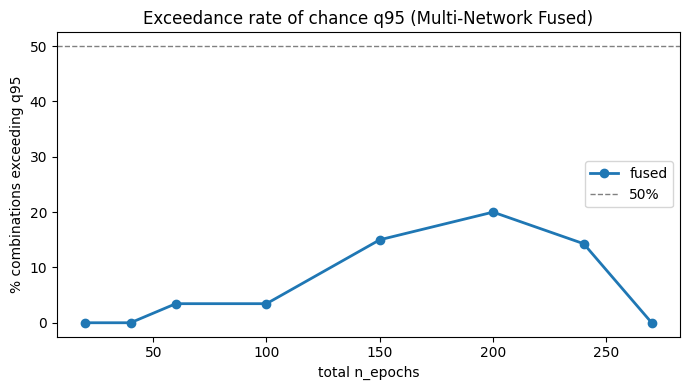

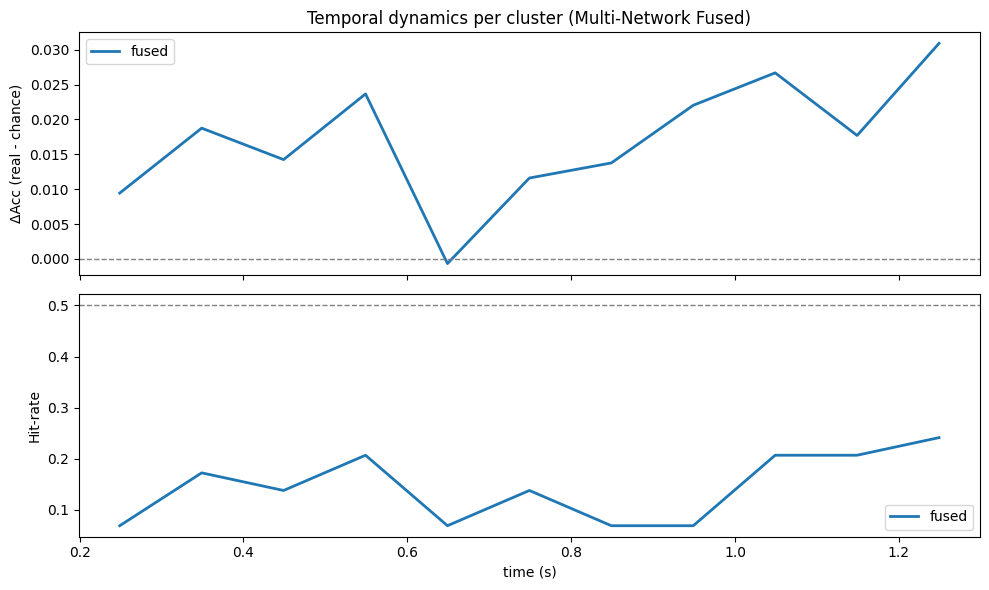


=== FINAL SUMMARY: Multi-Network Covariance Fusion (Theta ↔ Alpha) ===

fused (9 Theta + 13 Alfa = 22 channels):
  - Combinations exceeding q95: 9/162 (5.6%)
  - Average ΔAcc: 0.0207
  - Maximum Acc: 0.6850
  → Cross covariances Theta ↔ Alpha captured in Riemannian tangent space



In [12]:
# 7d) Rate of passing q95 per electrode
df_two["surpass_q95"] = (df_two["acc_real_mean"] > df_two["acc_chance_q95"]).astype(float)
surpass_tbl = (
    df_two.groupby(["electrode", "n_epochs_total"])["surpass_q95"].mean().unstack("electrode", fill_value=np.nan)
)

fig, ax = plt.subplots(figsize=(7, 4))
for elec in surpass_tbl.columns:
    ax.plot(
        surpass_tbl.index,
        100 * surpass_tbl[elec].values,
        marker="o",
        linewidth=2,
        label=elec,
    )
ax.axhline(50, color="gray", linestyle="--", linewidth=1, label="50%")
ax.set_xlabel("total n_epochs")
ax.set_ylabel("% combinations exceeding q95")
ax.set_title("Exceedance rate of chance q95 (Multi-Network Fused)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07d_surpass_rate_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7e) Temporal dynamics
ch_to_idx = {ch: i for i, ch in enumerate(CHANNEL_MODE)}
valid_targets = [e for e in target_electrodes if e in ch_to_idx]

if len(window_centers) < 2:
    # A single temporary window
    plt.figure(figsize=(6, 3))
    bars = []
    for elec in valid_targets:
        ci = ch_to_idx[elec]
        bars.append(float(mean_delta_map[ci, 0]))
    plt.bar(valid_targets, bars)
    plt.axhline(0.0, color="gray", linestyle="--", linewidth=1)
    plt.ylabel("ΔAcc (single window)")
    plt.title("Temporary summary (1 window) - Multi-Network Fused")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07e_temporal_dynamics_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    # Multiple time windows
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    for elec in valid_targets:
        ci = ch_to_idx[elec]
        axes[0].plot(window_centers, mean_delta_map[ci], linewidth=2, label=elec)
        axes[1].plot(window_centers, hit_rate_map[ci], linewidth=2, label=elec)

    axes[0].axhline(0.0, color="gray", linestyle="--", linewidth=1)
    axes[0].set_ylabel("ΔAcc (real - chance)")
    axes[0].set_title("Temporal dynamics per cluster (Multi-Network Fused)")
    axes[0].legend()

    axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
    axes[1].set_ylabel("Hit-rate")
    axes[1].set_xlabel("time (s)")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07e_temporal_dynamics_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Final summary
print("\n=== FINAL SUMMARY: Multi-Network Covariance Fusion (Theta ↔ Alpha) ===\n")
for elec in target_electrodes:
    dfe = df_two[df_two["electrode"] == elec]
    surpass = (dfe["acc_real_mean"] > dfe["acc_chance_q95"]).sum()
    total = len(dfe)
    avg_delta = dfe["delta_acc"].mean()
    max_acc = dfe["acc_real_mean"].max()
    print(f"{elec} (9 Theta + 13 Alfa = 22 channels):")
    print(f"  - Combinations exceeding q95: {surpass}/{total} ({100*surpass/total:.1f}%)")
    print(f"  - Average ΔAcc: {avg_delta:.4f}")
    print(f"  - Maximum Acc: {max_acc:.4f}")
    print(f"  → Cross covariances Theta ↔ Alpha captured in Riemannian tangent space")
    print()

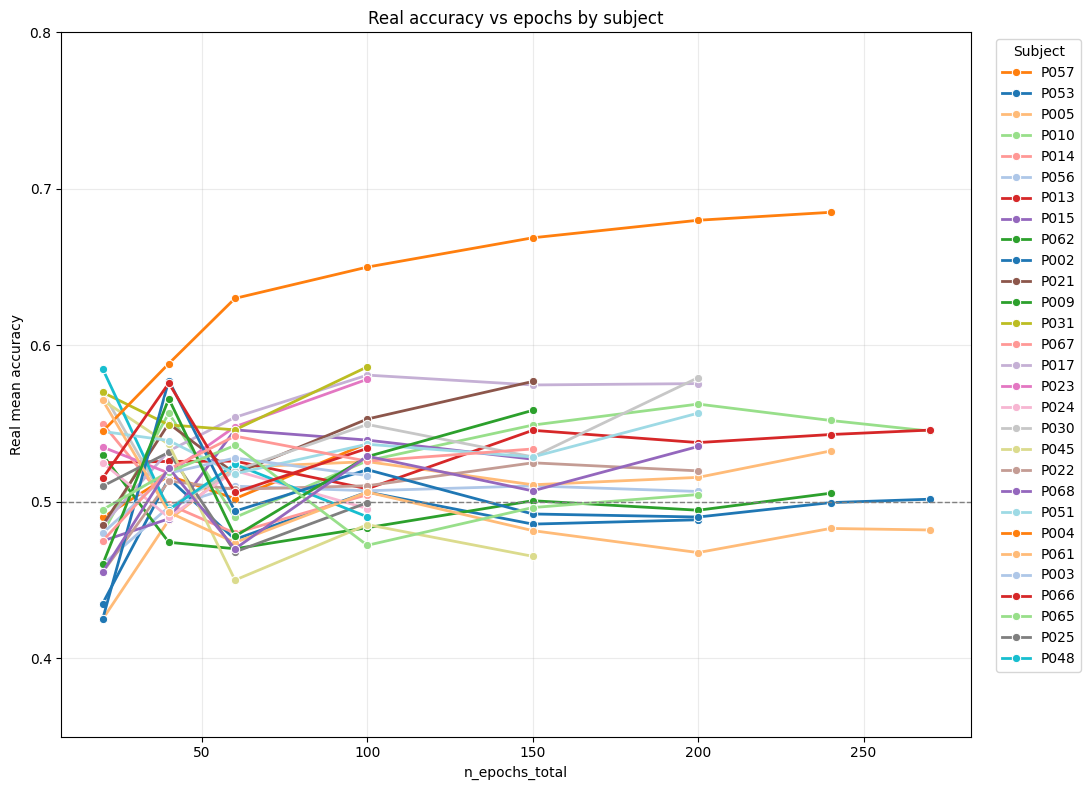

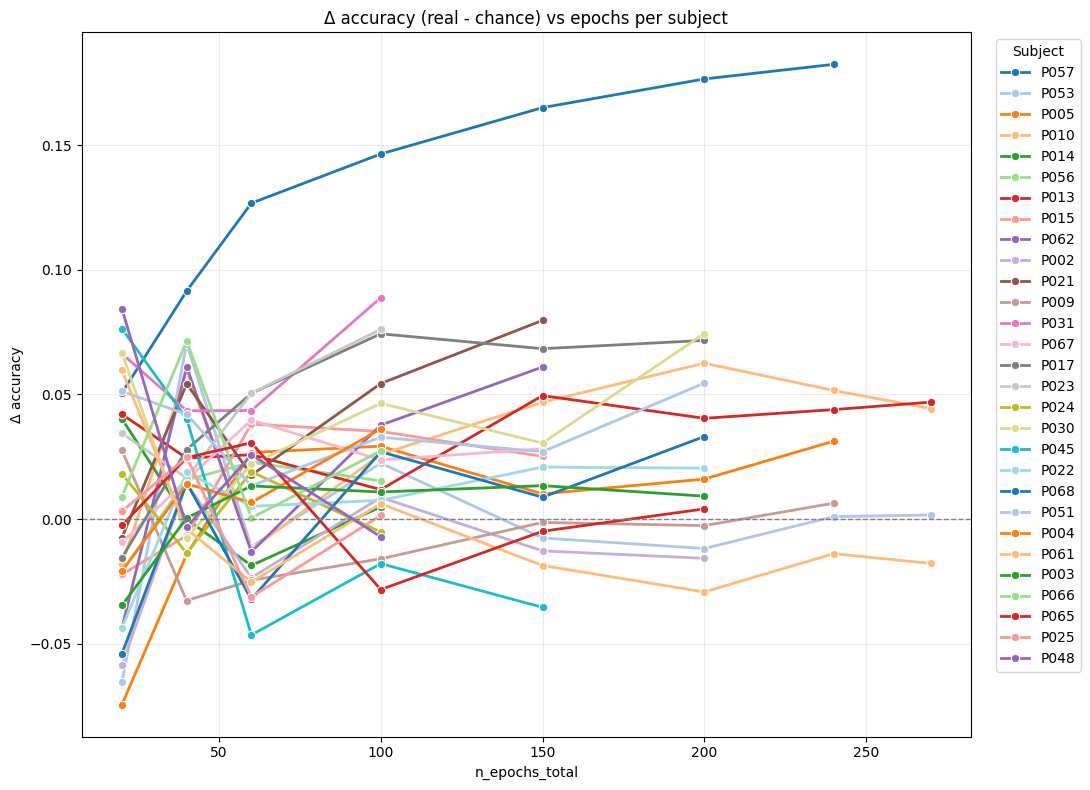

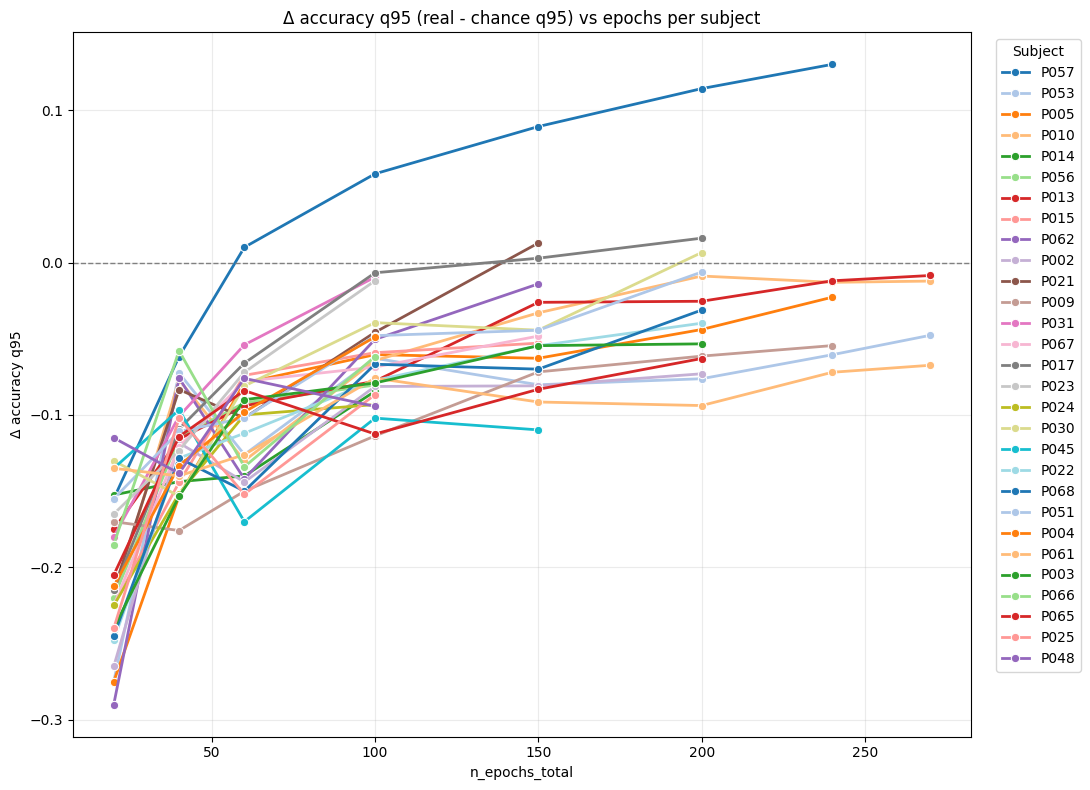

In [13]:
# Accuracy (real) according to number of epochs, with one line per subject
df_subj_acc = (
    df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)["acc_real_mean"]
    .mean()
    .sort_values(["subject", "n_epochs_total"])
)

plt.figure(figsize=(11, 8))
sns.lineplot(
    data=df_subj_acc,
    x="n_epochs_total",
    y="acc_real_mean",
    hue="subject",
    palette="tab20",
    marker="o",
    linewidth=2,
)
plt.title("Real accuracy vs epochs by subject")
plt.xlabel("n_epochs_total")
plt.ylabel("Real mean accuracy")
plt.ylim(0.35, 0.8)
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.grid(alpha=0.25)
subject_order = [s for s in pd.unique(subj_list) if s in df_subj_acc["subject"].unique()]

# Reorder the legend of the first plot according to subj_list
fig1 = plt.gcf()
ax1 = plt.gca()
handles, labels = ax1.get_legend_handles_labels()
hmap = {lab: h for h, lab in zip(handles, labels)}
ordered_labels = [s for s in subject_order if s in hmap]
ordered_handles = [hmap[s] for s in ordered_labels]
ax1.legend(ordered_handles, ordered_labels, title="Subject", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Extra plot: delta accuracy vs epochs per subject
df_subj_delta = (
    df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)["delta_acc"]
    .mean()
    .sort_values(["subject", "n_epochs_total"])
)

plt.figure(figsize=(11, 8))
sns.lineplot(
    data=df_subj_delta,
    x="n_epochs_total",
    y="delta_acc",
    hue="subject",
    hue_order=subject_order,
    palette="tab20",
    marker="o",
    linewidth=2,
)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Δ accuracy (real - chance) vs epochs per subject")
plt.xlabel("n_epochs_total")
plt.ylabel("Δ accuracy")
plt.grid(alpha=0.25)
plt.legend(title="Subject", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Extra plot: delta accuracy q95 vs epochs per subject
df_subj_delta_q95 = (
    df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)["delta_acc_q95"]
    .mean()
    .sort_values(["subject", "n_epochs_total"])
)

plt.figure(figsize=(11, 8))
sns.lineplot(
    data=df_subj_delta_q95,
    x="n_epochs_total",
    y="delta_acc_q95",
    hue="subject",
    hue_order=subject_order,
    palette="tab20",
    marker="o",
    linewidth=2,
)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Δ accuracy q95 (real - chance q95) vs epochs per subject")
plt.xlabel("n_epochs_total")
plt.ylabel("Δ accuracy q95")
plt.grid(alpha=0.25)
plt.legend(title="Subject", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

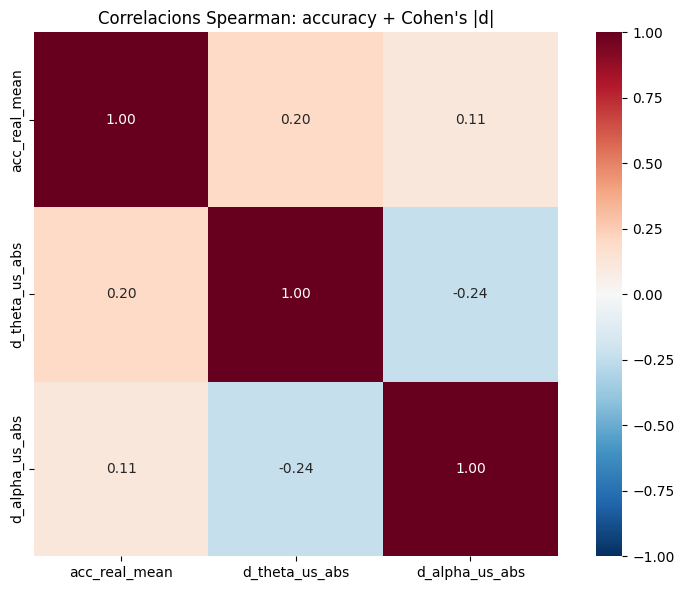

Matriu Spearman desada a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\figures


In [15]:
# 7f) Correlation matrix (Spearman) with Cohen's |d| only

acc_cols = ["acc_real_mean"]
acc_cols = [c for c in acc_cols if c in df_epochs.columns]
if len(acc_cols) == 0:
    raise RuntimeError("No accuracy columns found in df_epochs to calculate correlations.")

# Summary by subject to avoid duplication by n_epochs/electrode
df_acc_subject = df_epochs.groupby("subject", as_index=False)[acc_cols].mean().sort_values("subject")

# Selection metadata
df_meta = pd.read_csv(SELECTED_SUBJECTS_CSV).copy()

# Cohen's |d| columns only
cohen_cols = [c for c in ["d_theta_us_abs", "d_alpha_us_abs"] if c in df_meta.columns]
if len(cohen_cols) == 0:
    raise RuntimeError("No Cohen's |d| columns found in the selection CSV.")

for c in cohen_cols:
    df_meta[c] = pd.to_numeric(df_meta[c], errors="coerce")

df_corr_base = df_acc_subject.merge(df_meta[["subject"] + cohen_cols], on="subject", how="left")

corr_cols = acc_cols + cohen_cols
corr_spearman = df_corr_base[corr_cols].corr(method="spearman", numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True)
plt.title("Correlacions Spearman: accuracy + Cohen's |d|")
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07f_correlacio_spearman_accuracy_cohens_d_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Matriu Spearman desada a: {FIGURES_DIR}")

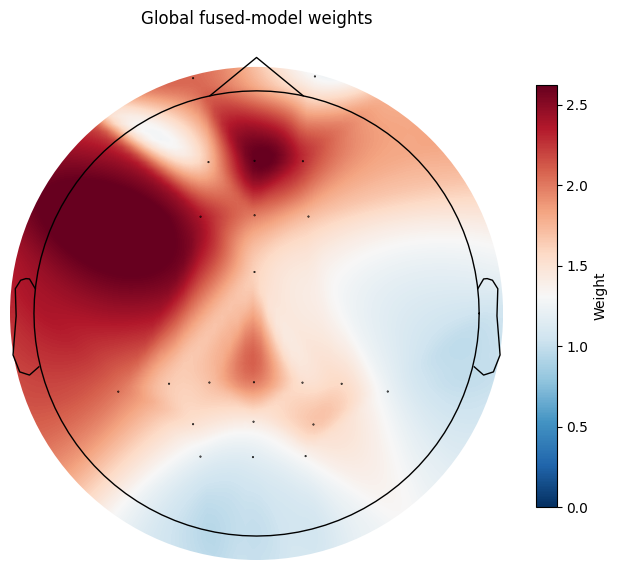

C:\Users\nils\AppData\Local\Temp\ipykernel_3272\3005758509.py:123: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights[order], y=[display_names[i] for i in order], palette="vlag", orient="h", ax=ax)


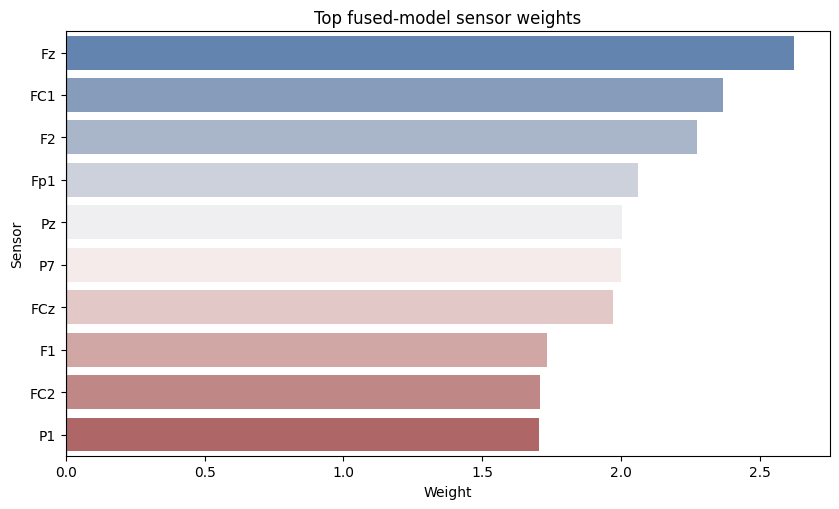

In [16]:
# 7g) Global model weights and spatial interpretation


def _resolve_topomap_names(n_sensors):
    # 0) Special case for chance level notebooks using TARGET_BAND_CHANNELS
    if "TARGET_BAND_CHANNELS" in globals() and len(TARGET_BAND_CHANNELS) == n_sensors:
        return [ch_name for ch_name, _ in TARGET_BAND_CHANNELS], [
            f"{ch_name}-{band}" for ch_name, band in TARGET_BAND_CHANNELS
        ]

    # 1) Best case: explicit fused channel names already available
    if "ch_names_dict" in globals() and isinstance(ch_names_dict, dict):
        for key in ("fused", "all", "common", "channels"):
            value = ch_names_dict.get(key)
            if isinstance(value, (list, tuple, np.ndarray)) and len(value) == n_sensors:
                names = [str(ch) for ch in value]
                return names, names

        # 2) Reconstruct fused names from theta+alpha lists
        theta_names = ch_names_dict.get("theta")
        alpha_names = ch_names_dict.get("alpha")
        if isinstance(theta_names, (list, tuple, np.ndarray)) and isinstance(alpha_names, (list, tuple, np.ndarray)):
            fused_names = [str(ch) for ch in theta_names] + [str(ch) for ch in alpha_names]
            if len(fused_names) == n_sensors:
                return fused_names, fused_names

        for value in ch_names_dict.values():
            if isinstance(value, (list, tuple, np.ndarray)) and len(value) == n_sensors:
                names = [str(ch) for ch in value]
                return names, names

    # 3) Reconstruct from target cluster definition (ordered theta+alpha)
    if "TARGET_BANDS_CLUSTERS" in globals() and isinstance(TARGET_BANDS_CLUSTERS, dict):
        ordered = []
        for band in ("theta", "alpha"):
            if band in TARGET_BANDS_CLUSTERS:
                ordered.extend([str(ch) for ch in TARGET_BANDS_CLUSTERS[band]])
        if len(ordered) == n_sensors:
            return ordered, ordered

    if "ch_names" in globals() and isinstance(ch_names, (list, tuple, np.ndarray)) and len(ch_names) == n_sensors:
        names = [str(ch) for ch in ch_names]
        return names, names

    if (
        "target_electrodes" in globals()
        and isinstance(target_electrodes, (list, tuple, np.ndarray))
        and len(target_electrodes) == n_sensors
    ):
        names = [str(ch) for ch in target_electrodes]
        return names, names

    fallback = [f"ch{i}" for i in range(n_sensors)]
    return fallback, fallback


def _weights_from_classifier(model, n_sensors):
    final_estimator = model.steps[-1][1] if hasattr(model, "steps") else model
    coef = np.asarray(getattr(final_estimator, "coef_", np.array([]))).ravel()
    if coef.size == 0:
        return np.zeros(n_sensors, dtype=float)
    if coef.size == n_sensors:
        return coef.astype(float)
    tri_size = n_sensors * (n_sensors + 1) // 2
    if coef.size == tri_size:
        weights = np.zeros(n_sensors, dtype=float)
        k = 0
        for i in range(n_sensors):
            for j in range(i, n_sensors):
                value = float(abs(coef[k]))
                if i == j:
                    weights[i] += value
                else:
                    weights[i] += 0.5 * value
                    weights[j] += 0.5 * value
                k += 1
        return weights
    return np.abs(np.resize(coef, n_sensors)).astype(float)


if "X_dict" not in globals() or "y" not in globals() or "fused" not in X_dict:
    print("Missing fused X/y for the interpretation plot.")
else:
    X_source = np.asarray(X_dict["fused"], dtype=np.float32)
    model = experiment.model_factory.make()
    model.fit(X_source, y)

    sensor_names, display_names = _resolve_topomap_names(X_source.shape[1])
    if len(sensor_names) != X_source.shape[1]:
        sensor_names = [f"ch{i}" for i in range(X_source.shape[1])]
        display_names = sensor_names

    weights = _weights_from_classifier(model, len(sensor_names))
    weights = np.nan_to_num(weights.astype(float), nan=0.0)

    info = mne.create_info(sensor_names, sfreq=1.0, ch_types="eeg")
    try:
        info.set_montage("standard_1020", on_missing="ignore")
    except Exception:
        pass

    fig, ax = plt.subplots(figsize=(6.8, 5.8))
    try:
        im, _ = mne.viz.plot_topomap(weights, info, axes=ax, show=False, cmap="RdBu_r", contours=0)
        fig.colorbar(im, ax=ax, shrink=0.8, label="Weight")
        ax.set_title("Global fused-model weights")
    except Exception:
        order = np.argsort(np.abs(weights))[::-1]
        ax.bar(
            np.arange(len(order)), weights[order], color=["tab:red" if weights[i] >= 0 else "tab:blue" for i in order]
        )
        ax.set_xticks(np.arange(len(order)))
        ax.set_xticklabels([display_names[i] for i in order], rotation=45, ha="right")
        ax.set_ylabel("Weight")
        ax.set_title("Global fused-model weights")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07g_fused_model_weights_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
    plt.show()

    top_n = min(10, len(weights))
    order = np.argsort(np.abs(weights))[::-1][:top_n]
    fig, ax = plt.subplots(figsize=(8.5, max(3.0, 0.42 * top_n + 1.0)))
    sns.barplot(x=weights[order], y=[display_names[i] for i in order], palette="vlag", orient="h", ax=ax)
    ax.axvline(0.0, color="0.5", linewidth=1)
    ax.set_title("Top fused-model sensor weights")
    ax.set_xlabel("Weight")
    ax.set_ylabel("Sensor")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07g_fused_model_weights_bar_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 8. ROC/PR Curves and Final Model Training

Saved out-of-fold predictions to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\cache\oof_predictions_im_vs_ip_riemann_fused.npz

GLOBAL COHORT CROSS-VALIDATION SUMMARY
Label: fused
  Fold 5 Accuracy: 0.5477 ± 0.0946
  Average CV Accuracy: 0.5325 ± 0.0991


AGGREGATED CLASSIFICATION REPORT FOR LABEL: fused
              precision    recall  f1-score   support

           0       0.54      0.53      0.53      2373
           1       0.53      0.54      0.54      2373

    accuracy                           0.53      4746
   macro avg       0.53      0.53      0.53      4746
weighted avg       0.53      0.53      0.53      4746




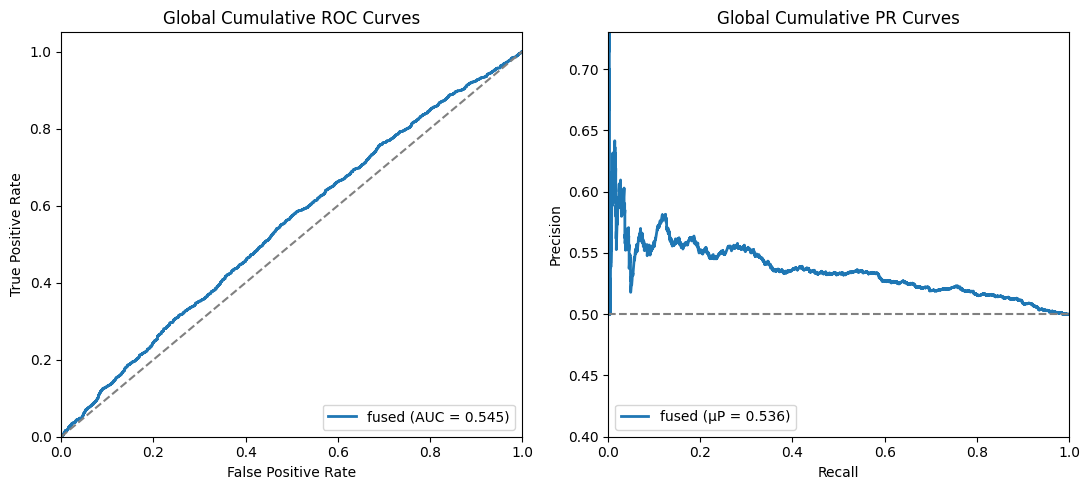

Saved global cumulative ROC/PR plots.

INDIVIDUAL SUBJECT DETAILED PERFORMANCE

Classification Report for Subject P057 (fused):
              precision    recall  f1-score   support

           0       0.68      0.69      0.69       100
           1       0.69      0.68      0.68       100

    accuracy                           0.69       200
   macro avg       0.69      0.69      0.68       200
weighted avg       0.69      0.69      0.68       200

Fold 5 Accuracy: 0.7000
Average CV Accuracy: 0.6850 ± 0.0490



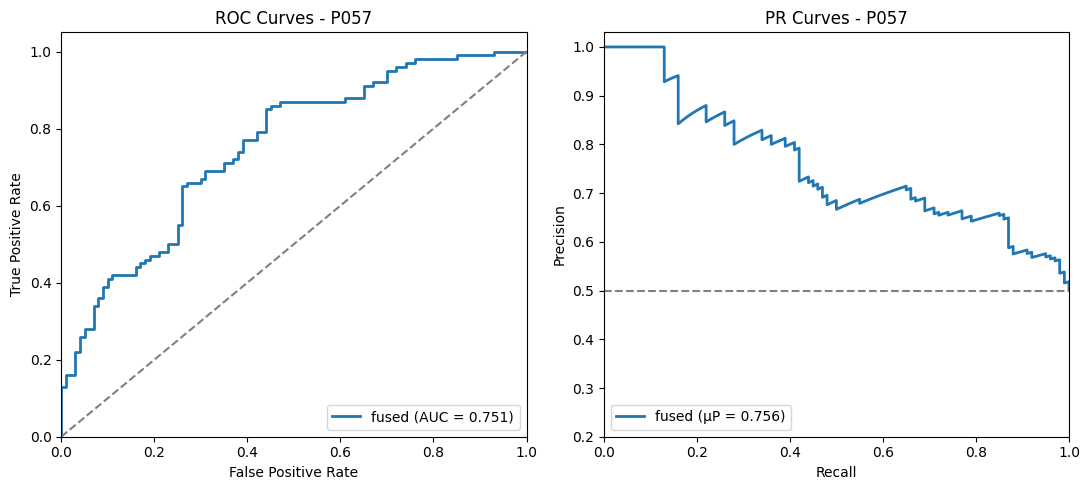

Saved final models and plots for P057


Classification Report for Subject P053 (fused):
              precision    recall  f1-score   support

           0       0.53      0.53      0.53       120
           1       0.53      0.53      0.53       120

    accuracy                           0.53       240
   macro avg       0.53      0.53      0.53       240
weighted avg       0.53      0.53      0.53       240

Fold 5 Accuracy: 0.6042
Average CV Accuracy: 0.5292 ± 0.0705


Classification Report for Subject P005 (fused):
              precision    recall  f1-score   support

           0       0.53      0.48      0.50       100
           1       0.52      0.57      0.55       100

    accuracy                           0.53       200
   macro avg       0.53      0.52      0.52       200
weighted avg       0.53      0.53      0.52       200

Fold 5 Accuracy: 0.5250
Average CV Accuracy: 0.5250 ± 0.0316


Classification Report for Subject P010 (fused):
              precision    recall  f

In [22]:
oof_save_dict = {}
all_fold_accuracies = {lbl: {1: [], 2: [], 3: [], 4: [], 5: []} for lbl in CHANNEL_MODE}
individual_reports = []

subject_ids = pd.unique(subj_list).tolist()

# Define MODELS_DIR
MODELS_DIR = CACHE_DIR / "weights"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

X = X_dict if "X_dict" in globals() else (X if "X" in globals() else None)

# We only plot ROC/PR curves for one target subject and the global cumulative across all subjects
plot_subj_target = "P057"
if plot_subj_target not in subject_ids:
    plot_subj_target = subject_ids[0] if subject_ids else None

for subj_name in subject_ids:
    subj_mask = subj_list == subj_name
    y_s = y[subj_mask]

    if len(np.unique(y_s)) < 2:
        continue

    should_plot = subj_name == plot_subj_target
    if should_plot:
        fig, axes = plt.subplots(1, 2, figsize=(11, 5))

    # Save true labels
    oof_save_dict[f"{subj_name}_y_true"] = y_s

    labels_to_eval = CHANNEL_MODE

    for ch_idx, label in enumerate(labels_to_eval):
        # Extract features
        # X is X_dict
        X_feat = X[label][subj_mask]

        n_splits = choose_n_splits(y_s, max_splits=5)
        splits = temporal_stratified_splits(y_s, n_splits)

        # Out-of-fold prediction array
        oof_probs = np.full(len(y_s), np.nan)

        fold_accs = []
        for fold_idx, (tr, te) in enumerate(splits, start=1):
            model = experiment.model_factory.make()
            model.fit(X_feat[tr], y_s[tr])
            # Predict probabilities
            probs = model.predict_proba(X_feat[te])[:, 1]
            oof_probs[te] = probs
            acc = np.mean((probs >= 0.5).astype(int) == y_s[te])
            fold_accs.append(acc)
            all_fold_accuracies[label][fold_idx].append(acc)

        valid_mask = ~np.isnan(oof_probs)
        y_valid = y_s[valid_mask]
        preds_valid = oof_probs[valid_mask]

        oof_save_dict[f"{subj_name}_{label}_prob"] = oof_probs

        y_pred = (preds_valid >= 0.5).astype(int)
        rep_str = (
            f"\nClassification Report for Subject {subj_name} ({label}):\n"
            f"{classification_report(y_valid, y_pred)}\n"
            f"Fold 5 Accuracy: {fold_accs[-1]:.4f}\n"
            f"Average CV Accuracy: {np.mean(fold_accs):.4f} ± {np.std(fold_accs):.4f}\n"
        )
        individual_reports.append(rep_str)

        if should_plot:
            # Compute ROC
            fpr, tpr, _ = roc_curve(y_valid, preds_valid)
            roc_auc = auc(fpr, tpr)
            axes[0].plot(fpr, tpr, label=f"{label} (AUC = {roc_auc:.3f})", linewidth=2)

            # Compute PR
            precision, recall, _ = precision_recall_curve(y_valid, preds_valid)
            ap = average_precision_score(y_valid, preds_valid)
            axes[1].plot(recall, precision, label=f"{label} (μP = {ap:.3f})", linewidth=2)

        # Train final model on ALL data for this subject/channel
        final_model = experiment.model_factory.make()
        final_model.fit(X_feat, y_s)

        # Save model
        model_filename = MODELS_DIR / f"final_model_{TASK_TAG}_{subj_name}_{label}.joblib"
        joblib.dump(final_model, model_filename)

    if should_plot:
        # Formatting plots
        axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--")
        axes[0].set_xlim([0.0, 1.0])
        axes[0].set_ylim([0.0, 1.05])
        axes[0].set_xlabel("False Positive Rate")
        axes[0].set_ylabel("True Positive Rate")
        axes[0].set_title(f"ROC Curves - {subj_name}")
        axes[0].legend(loc="lower right")

        axes[1].axhline(0.5, color="grey", linestyle="--")
        axes[1].set_xlim([0.0, 1.0])
        axes[1].set_ylim([0.2, 1.03])
        axes[1].set_xlabel("Recall")
        axes[1].set_ylabel("Precision")
        axes[1].set_title(f"PR Curves - {subj_name}")
        axes[1].legend(loc="lower left")

        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f"roc_pr_curves_{subj_name}.png", dpi=150)
        individual_reports.append(fig)
        plt.close(fig)
        individual_reports.append(f"Saved final models and plots for {subj_name}\n")

# Save out-of-fold predictions for future comparison
np.savez_compressed(CACHE_DIR / f"oof_predictions_{TASK_TAG}.npz", **oof_save_dict)
print(f"Saved out-of-fold predictions to: {CACHE_DIR / f'oof_predictions_{TASK_TAG}.npz'}")

# Global Cohort CV Summary
print("\n" + "=" * 50)
print("GLOBAL COHORT CROSS-VALIDATION SUMMARY")
for label in all_fold_accuracies.keys():
    fold_dict = all_fold_accuracies[label]
    fold5_mean = np.mean(fold_dict[5]) if fold_dict[5] else 0.0
    fold5_std = np.std(fold_dict[5]) if fold_dict[5] else 0.0
    pooled_cv = [val for fold_vals in fold_dict.values() for val in fold_vals]
    mean_cv = np.mean(pooled_cv) if pooled_cv else 0.0
    std_cv = np.std(pooled_cv) if pooled_cv else 0.0
    print(f"Label: {label}")
    print(f"  Fold 5 Accuracy: {fold5_mean:.4f} ± {fold5_std:.4f}")
    print(f"  Average CV Accuracy: {mean_cv:.4f} ± {std_cv:.4f}")
print("=" * 50 + "\n")

# Aggregated classification report and global cumulative ROC/PR curves across all subjects
fig_global, axes_global = plt.subplots(1, 2, figsize=(11, 5))

for label in labels_to_eval:
    y_true_lbl = []
    y_pred_lbl = []
    y_prob_lbl = []
    for subj_name in subject_ids:
        if f"{subj_name}_y_true" in oof_save_dict and f"{subj_name}_{label}_prob" in oof_save_dict:
            y_s = oof_save_dict[f"{subj_name}_y_true"]
            probs = oof_save_dict[f"{subj_name}_{label}_prob"]
            valid = ~np.isnan(probs)
            y_true_lbl.extend(y_s[valid])
            y_prob_lbl.extend(probs[valid])
            y_pred_lbl.extend((probs[valid] >= 0.5).astype(int))

    if y_true_lbl:
        print("\n" + "=" * 50)
        print(f"AGGREGATED CLASSIFICATION REPORT FOR LABEL: {label}")
        print("=" * 50)
        print(classification_report(y_true_lbl, y_pred_lbl))
        print("=" * 50 + "\n")

        # Compute global ROC
        fpr, tpr, _ = roc_curve(y_true_lbl, y_prob_lbl)
        roc_auc = auc(fpr, tpr)
        axes_global[0].plot(fpr, tpr, label=f"{label} (AUC = {roc_auc:.3f})", linewidth=2)

        # Compute global PR
        precision, recall, _ = precision_recall_curve(y_true_lbl, y_prob_lbl)
        ap = average_precision_score(y_true_lbl, y_prob_lbl)
        axes_global[1].plot(recall, precision, label=f"{label} (μP = {ap:.3f})", linewidth=2)

# Formatting global plots
axes_global[0].plot([0, 1], [0, 1], color="grey", linestyle="--")
axes_global[0].set_xlim([0.0, 1.0])
axes_global[0].set_ylim([0.0, 1.05])
axes_global[0].set_xlabel("False Positive Rate")
axes_global[0].set_ylabel("True Positive Rate")
axes_global[0].set_title("Global Cumulative ROC Curves")
axes_global[0].legend(loc="lower right")

axes_global[1].axhline(0.5, color="grey", linestyle="--")
axes_global[1].set_xlim([0.0, 1.0])
axes_global[1].set_ylim([0.4, 0.73])
axes_global[1].set_xlabel("Recall")
axes_global[1].set_ylabel("Precision")
axes_global[1].set_title("Global Cumulative PR Curves")
axes_global[1].legend(loc="lower left")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "roc_pr_curves_global.png", dpi=150)
plt.show()
print("Saved global cumulative ROC/PR plots.")

# Display individual subject details
print("\n" + "=" * 60)
print("INDIVIDUAL SUBJECT DETAILED PERFORMANCE")
print("=" * 60)
for item in individual_reports:
    if isinstance(item, str):
        print(item)
    else:
        from IPython.display import display

        display(item)